# Azure Predictive Maintenance — Phase 2A exploratory analysis

This notebook examines the five committed Azure CSV files through the validated `fedmaint.data.azure` loader and reusable `fedmaint.data.eda` summaries. It is descriptive EDA only: no labels, prediction windows, model training, or factory split are defined here.

**Run from the repository root** with Python 3.9+ and `pandas`, `numpy`, `matplotlib`, `ipykernel` installed. The notebook also resolves the repository root when opened from `notebooks/`. The full-data summary takes roughly a minute on this machine because every telemetry row is validated. Charts render from a deterministic 10,000-row telemetry reservoir sample; numerical statistics and correlations use all rows.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Run this notebook from the repository root or notebooks/ directory")
sys.path.insert(0, str(ROOT / "src"))

from fedmaint.data.azure import DEFAULT_AZURE_DIR
from fedmaint.data.eda import SENSORS, analyze_azure

plt.style.use("seaborn-v0_8-whitegrid")
print("Azure source:", DEFAULT_AZURE_DIR)
print("Repository:", ROOT)

Azure source: C:\Users\moman\Desktop\NewTrend Project\FedMaint-AI\data\Azure Data
Repository: C:\Users\moman\Desktop\NewTrend Project\FedMaint-AI


## 1. Source dimensions and data quality

The loader checks schemas, types, timestamps, and machine references before a record is included. The summary counts exact duplicate rows and required-field missing values. A malformed required field would stop execution with its source filename and CSV row number; it would not silently appear as a missing value in the tables below.

In [2]:
summary = analyze_azure(DEFAULT_AZURE_DIR, sample_size=10_000, seed=42)
quality = pd.DataFrame([
    {
        "table": table,
        "rows": profile["rows"],
        "columns": len(profile["columns"]),
        "missing required values": sum(profile["missing_values"].values()),
        "exact duplicate rows": profile["exact_duplicate_rows"],
        "first timestamp": profile["first_timestamp"],
        "last timestamp": profile["last_timestamp"],
    }
    for table, profile in summary["tables"].items()
]).set_index("table")
display(quality)
display(pd.DataFrame.from_dict(
    {name: profile["missing_values"] for name, profile in summary["tables"].items()},
    orient="index",
).fillna("—").rename_axis("table"))

,rows,columns,missing required values,exact duplicate rows,first timestamp,last timestamp
table,,,,,,
machines,100,3,0,0,NaT,NaT
telemetry,876100,6,0,0,2015-01-01 06:00:00,2016-01-01 06:00:00
errors,3919,3,0,0,2015-01-01 06:00:00,2016-01-01 05:00:00
maint,3286,3,0,0,2014-06-01 06:00:00,2016-01-01 06:00:00
failures,761,3,0,0,2015-01-02 03:00:00,2015-12-31 06:00:00


,machineID,model,age,datetime,volt,rotate,pressure,vibration,errorID,comp,failure
table,,,,,,,,,,,
machines,0,0.0,0.0,—,—,—,—,—,—,—,—
telemetry,0,—,—,0.0,0.0,0.0,0.0,0.0,—,—,—
errors,0,—,—,0.0,—,—,—,—,0.0,—,—
maint,0,—,—,0.0,—,—,—,—,—,0.0,—
failures,0,—,—,0.0,—,—,—,—,—,—,0.0


**Observed:** The files contain 100 machines, 876,100 telemetry records, 3,919 errors, 3,286 maintenance events, and 761 failure events. The validated required fields have zero missing values, and no exact duplicate rows were found. Telemetry runs from 2015-01-01 06:00 through 2016-01-01 06:00; maintenance history begins earlier, on 2014-06-01. These are source-record coverage dates, not train/test boundaries. No conclusion about missing *time intervals* follows from the zero missing-field count.

## 2. Machine metadata

Counts describe the provided machine models. They do not establish or approve a federated client split or held-out factory.

,machines
model1,16
model2,17
model3,35
model4,32


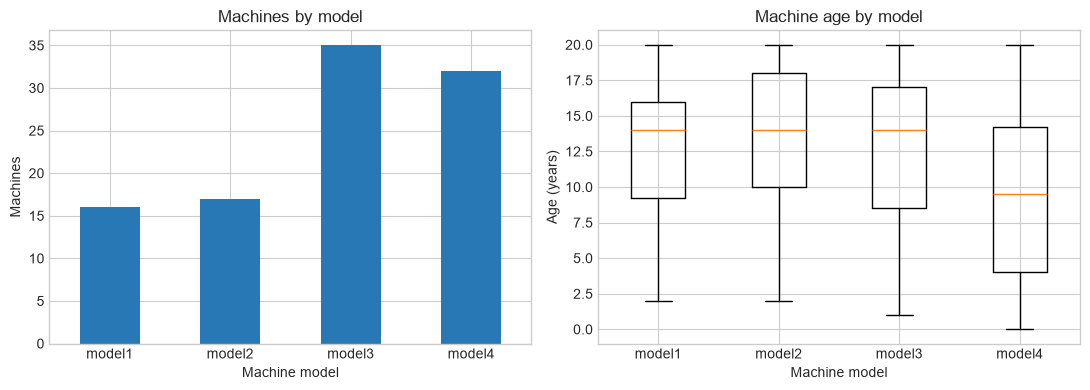

In [3]:
models = pd.Series(summary["machines_by_model"], name="machines")
display(models.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
models.plot.bar(ax=axes[0], color="#2878B5")
axes[0].set(title="Machines by model", xlabel="Machine model", ylabel="Machines")
axes[0].tick_params(axis="x", rotation=0)
age_groups = [summary["ages_by_model"][model] for model in models.index]
axes[1].boxplot(age_groups, tick_labels=list(models.index))
axes[1].set(title="Machine age by model", xlabel="Machine model", ylabel="Age (years)")
fig.tight_layout()
plt.show()

**Observed:** Model counts are 16 (model1), 17 (model2), 35 (model3), and 32 (model4). The unequal group sizes matter when interpreting raw event counts; this notebook does not choose a holdout.

## 3. Telemetry distributions and pairwise correlations

Means, population standard deviations, ranges, and Pearson correlations use all 876,100 validated telemetry rows. Histograms use the deterministic 10,000-row reservoir sample for display; they are approximate visual distributions. Global pairwise correlations do not describe within-machine temporal relationships or associations with failures.

,count,mean,std_population,min,max
volt,876100.0,170.778,15.509,97.334,255.125
rotate,876100.0,446.605,52.674,138.432,695.021
pressure,876100.0,100.859,11.049,51.237,185.952
vibration,876100.0,40.385,5.370,14.877,76.791


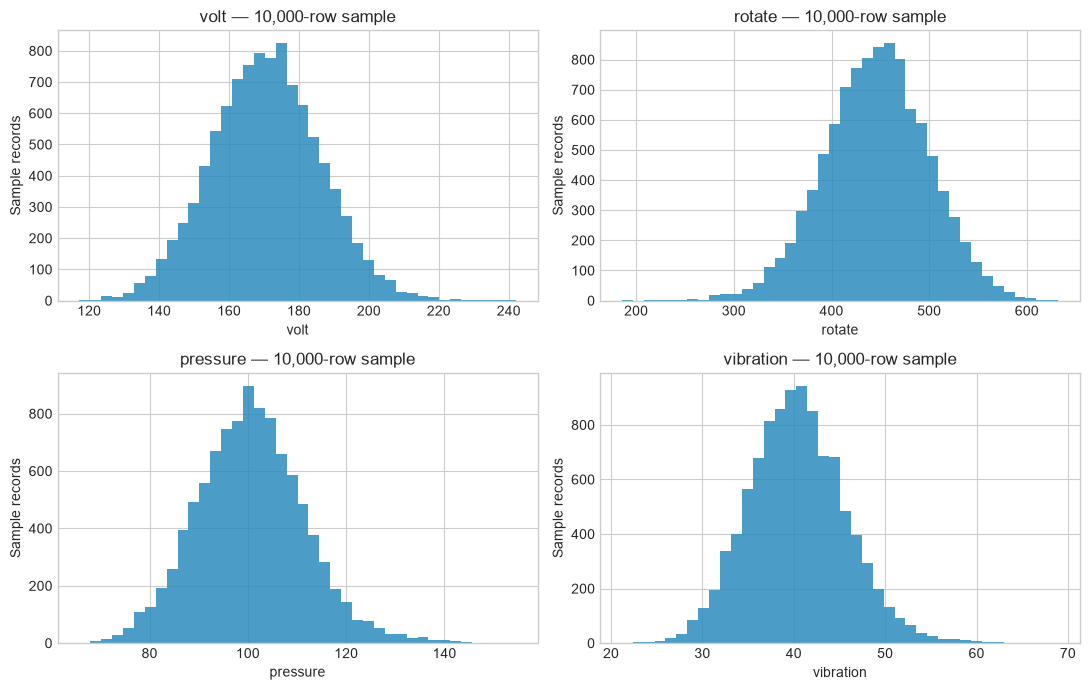

In [4]:
sensor_stats = pd.DataFrame(summary["sensor_stats"]).T
display(sensor_stats.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, sensor in zip(axes.flat, SENSORS):
    ax.hist(summary["telemetry_plot_sample"][sensor], bins=40, color="#2B8CBE", alpha=0.85)
    ax.set(title=f"{sensor} — 10,000-row sample", xlabel=sensor, ylabel="Sample records")
fig.tight_layout()
plt.show()

,volt,rotate,pressure,vibration
volt,1.0000,-0.0015,0.0017,0.0024
rotate,-0.0015,1.0000,-0.0007,-0.0031
pressure,0.0017,-0.0007,1.0000,0.0014
vibration,0.0024,-0.0031,0.0014,1.0000


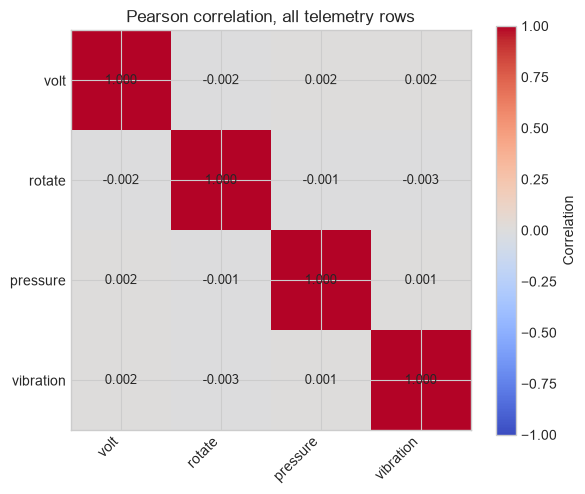

In [5]:
correlation = pd.DataFrame(summary["sensor_correlation"]).loc[list(SENSORS), list(SENSORS)]
display(correlation.round(4))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(correlation.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(SENSORS)), SENSORS, rotation=45, ha="right")
ax.set_yticks(range(len(SENSORS)), SENSORS)
ax.set_title("Pearson correlation, all telemetry rows")
for i in range(len(SENSORS)):
    for j in range(len(SENSORS)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.3f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

**Observed:** Across all telemetry rows, mean voltage is about 170.78, rotation 446.61, pressure 100.86, and vibration 40.39. All six off-diagonal global sensor correlations have absolute magnitude below 0.004. These near-zero aggregate correlations do not rule out machine-specific or time-dependent structure. Extreme observed values are descriptive ranges, not diagnosed faults or an approved outlier-removal rule.

## 4. Error, maintenance, and failure events

These are observed *event-record counts*. A failure-event count is not the number of positive future-failure training windows, and no proposed 24-hour prediction horizon is used here. Category counts are not rates: models and machines have different denominators and observation histories.

Error codes


,event records
error1,1010
error2,988
error3,838
error4,727
error5,356


Maintenance components


,event records
comp1,804
comp2,863
comp3,808
comp4,811


Failure components


,event records
comp1,192
comp2,259
comp3,131
comp4,179


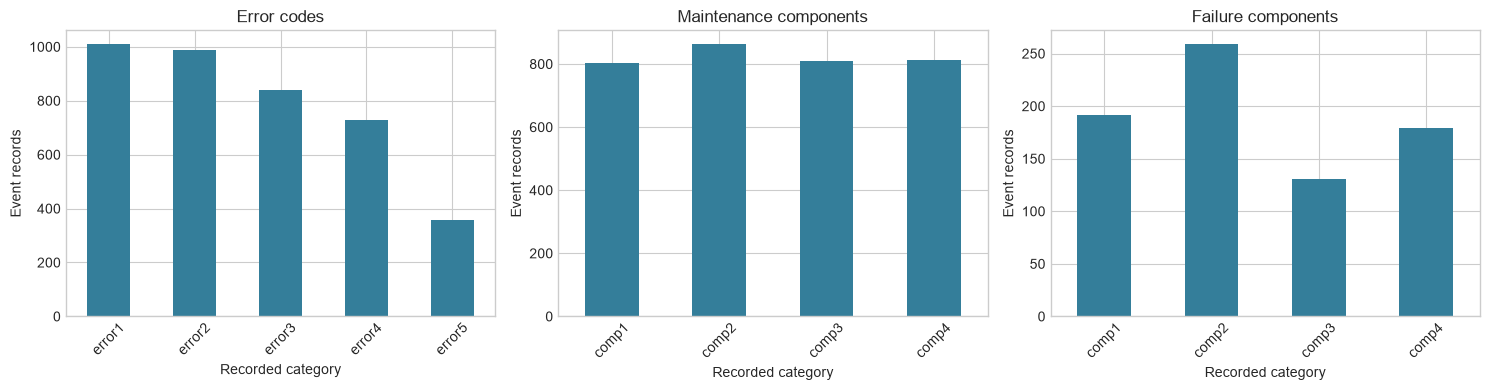

In [6]:
for table, label in (("errors", "Error codes"), ("maint", "Maintenance components"), ("failures", "Failure components")):
    values = pd.Series(summary["event_counts"][table], name="event records")
    print(label)
    display(values.to_frame())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, table, title in zip(
    axes,
    ("errors", "maint", "failures"),
    ("Error codes", "Maintenance components", "Failure components"),
):
    pd.Series(summary["event_counts"][table]).plot.bar(ax=ax, color="#347E9A")
    ax.set(title=title, xlabel="Recorded category", ylabel="Event records")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

,errors,maint,failures
2014-06,—,63,—
2014-07,—,78,—
2014-08,—,57,—
2014-09,—,51,—
2014-10,—,54,—
2014-11,—,56,—
2014-12,—,41,—
2015-01,356.0,196,94.0
2015-02,291.0,204,50.0
2015-03,351.0,238,59.0


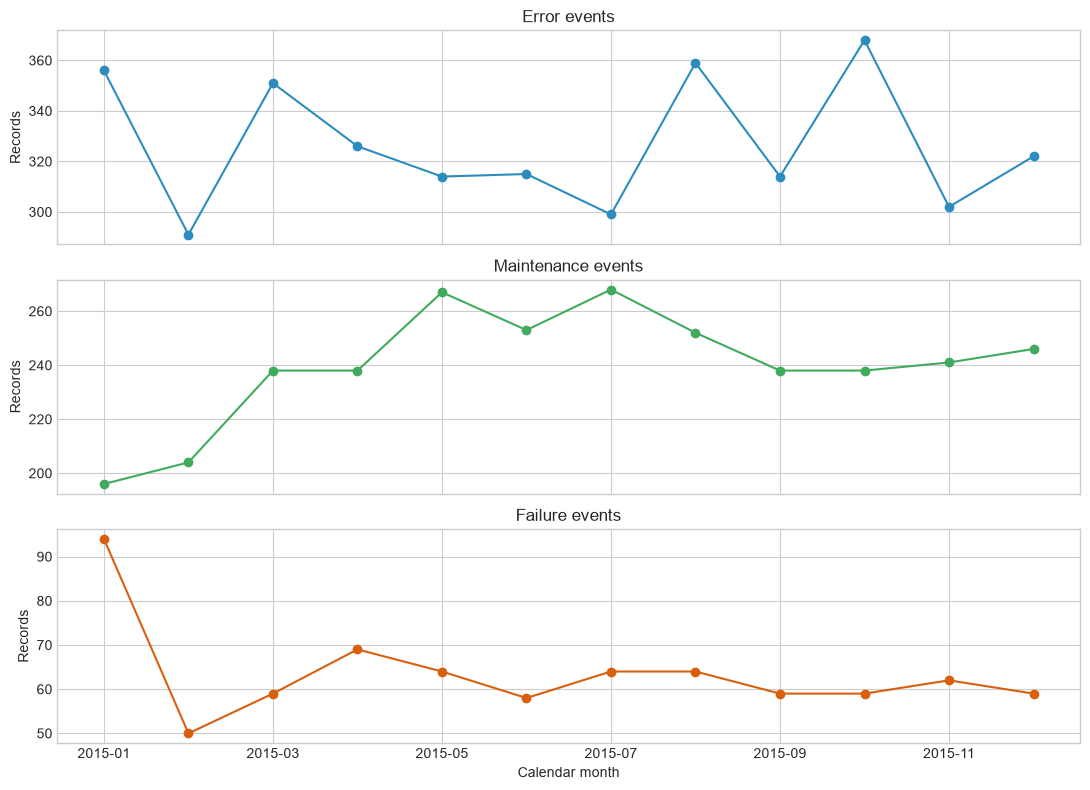

In [7]:
event_months = pd.DataFrame({
    table: pd.Series(summary["monthly_counts"][table])
    for table in ("errors", "maint", "failures")
})
display(event_months.fillna("—"))
plot_months = event_months.loc["2015-01":"2015-12"]
axes = plot_months.plot(subplots=True, layout=(3, 1), figsize=(11, 8), marker="o",
                         legend=False, sharex=True, color=["#2B8CBE", "#41AB5D", "#D95F0E"])
for ax, title in zip(axes.flat, ("Error events", "Maintenance events", "Failure events")):
    ax.set(title=title, ylabel="Records")
axes.flat[-1].set_xlabel("Calendar month")
plt.tight_layout()
plt.show()

**Observed:** Error counts are highest for `error1` (1,010) and lowest for `error5` (356). Maintenance records are distributed across `comp1`–`comp4` (804, 863, 808, 811); failure events across those components number 192, 259, 131, and 179 respectively. Maintenance begins seven months before telemetry coverage. Endpoint months are partial, so their raw monthly counts should not be compared to full months as rates.

## Interpretation limits and next decisions

The Azure data are simulated. This notebook reports source-table quality, univariate sensor summaries, global correlations, and event frequencies. It does **not** infer failure causes, detect outliers with a selected threshold, join future events into predictors, derive labels, or select a time horizon, held-out factory, model architecture, or federated setup. Source timestamps have no timezone metadata; they are treated as naive timestamps. Histogram shapes come from a bounded sample, while counts and aggregate statistics use all validated records. Any future modeling analysis must define observation windows and leakage-safe temporal boundaries separately.